# Lab Assignment

### 1. Create a scatterplot based on the dataset using two variables, namely Avg_Credit_Limit and Total_credit_card. Can the distribution of the data be considered linear?

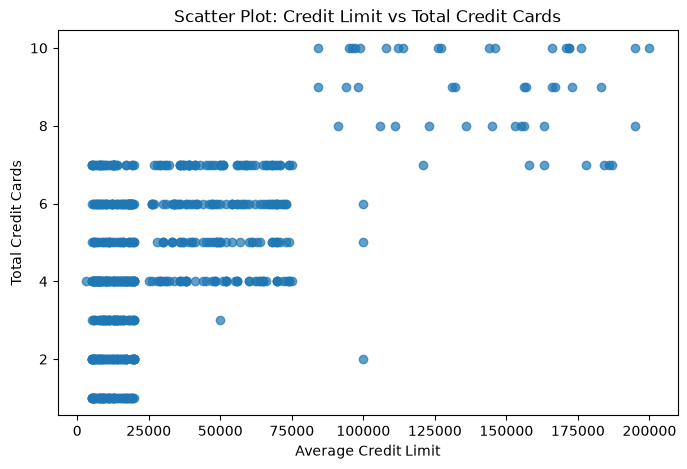

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("CC_Customer_Dataset.csv")

plt.figure(figsize=(8, 5))
plt.scatter(
    df["Avg_Credit_Limit"],
    df["Total_Credit_Cards"],
    alpha=0.7
)

plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.title("Scatter Plot: Credit Limit vs Total Credit Cards")
plt.show()

### 2. Construct a clustering model using the K-Means algorithm. Determine the optimal number k using elbow method. Supplement your analysis with line chart and provide an analytical rationale for why you selected that value.

c:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

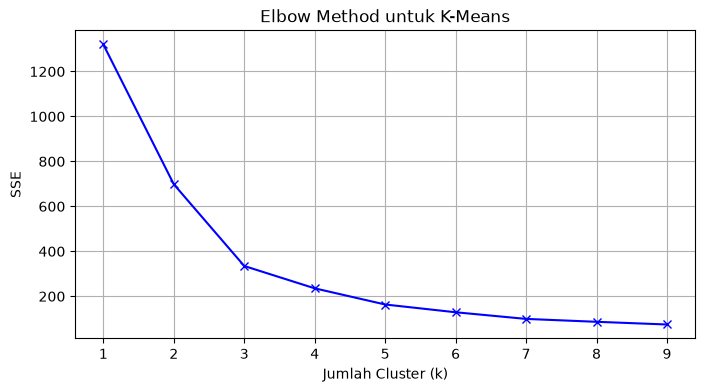

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features_kmeans = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards"
]

X_kmeans = df[features_kmeans]

scaler_kmeans = StandardScaler()
X_scaled = scaler_kmeans.fit_transform(X_kmeans)

sse = []
K = range(1, 10)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    sse.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("SSE")
plt.title("Elbow Method untuk K-Means")
plt.xticks(list(K))
plt.grid(True)
plt.show()

### 3. Depict the clustering results from the K-Means model using a scatter plot.

c:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


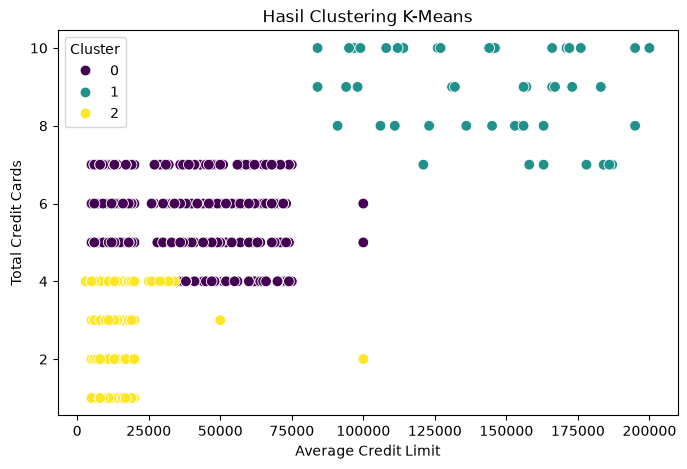

KMeans_Cluster
0    330
1     48
2    282
Name: count, dtype: int64


In [4]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Avg_Credit_Limit",
    y="Total_Credit_Cards",
    hue="KMeans_Cluster",
    palette="viridis",
    s=60
)

plt.title("Hasil Clustering K-Means")
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.legend(title="Cluster")
plt.show()

print(df["KMeans_Cluster"].value_counts().sort_index())

### 4. Construct a clustering model using DBSCAN with all usable variables.

In [5]:
from sklearn.cluster import DBSCAN

features_dbscan = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made"
]

X_dbscan = df[features_dbscan]

scaler_dbscan = StandardScaler()
X_dbscan_scaled = scaler_dbscan.fit_transform(X_dbscan)

dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_dbscan_scaled)

print("Jumlah anggota setiap label:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

print("\nJumlah cluster:",
      len(set(df["DBSCAN_Cluster"]) - {-1}))

print("Jumlah noise:",
      (df["DBSCAN_Cluster"] == -1).sum())

Jumlah anggota setiap label:
DBSCAN_Cluster
-1     44
 0    606
 1     10
Name: count, dtype: int64

Jumlah cluster: 2
Jumlah noise: 44


### 5. Determine the number k using elbow method. Supplement your analysis with line chart and provide an analytical rationale for why you selected that value.

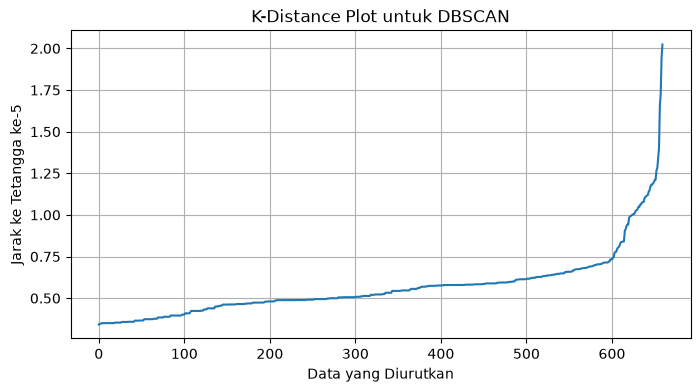

In [6]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_dbscan_scaled)

distances, indices = neighbors_fit.kneighbors(X_dbscan_scaled)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.xlabel("Data yang Diurutkan")
plt.ylabel("Jarak ke Tetangga ke-5")
plt.title("K-Distance Plot untuk DBSCAN")
plt.grid(True)
plt.show()

### 6. Determine the value of the silhouette score and the DBI of the DBSCAN model.

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

labels = df["DBSCAN_Cluster"].values
mask = labels != -1

X_eval = X_dbscan_scaled[mask]
labels_eval = labels[mask]

n_clusters = len(set(labels_eval))

if n_clusters >= 2:
    silhouette = silhouette_score(X_eval, labels_eval)
    dbi = davies_bouldin_score(X_eval, labels_eval)

    print("Silhouette Score:", round(silhouette, 4))
    print("Davies-Bouldin Index:", round(dbi, 4))
else:
    print("Metrik tidak dapat dihitung karena cluster valid kurang dari 2.")

Silhouette Score: 0.5445
Davies-Bouldin Index: 0.5154


#### Hasil Analisis:
- Silhouette Score: semakin mendekati 1, semakin baik pemisahan cluster. Nilai sekitar 0,545 menunjukkan pemisahan yang cukup baik pada data yang dievaluasi.
- DBI: semakin kecil nilainya, semakin baik kekompakan dan pemisahan cluster. Nilai sekitar 0,515 menunjukkan hasil yang cukup baik.
- Noise: DBSCAN tidak harus memasukkan semua pelanggan ke dalam cluster. Data noise perlu diperhatikan karena pengeluarannya dari evaluasi dapat memengaruhi interpretasi kedua metrik.